In [2]:
import json
import re
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None )


In [3]:
DATA_PATH = Path("../data/bronze/categoria=eletronicos/data_extracao=2026-07-08/produtos.parquet")

df = pd.read_parquet(DATA_PATH)

print(f"L : {df.shape[0]}")
print(f"C : {df.shape[1]}")
print(f"{df.memory_usage(deep=True).sum() / 1024:.1f} KB")

L : 48
C : 26
64.4 KB


In [4]:
df.head()

,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,book_format,product_url,product_photo,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,climate_pledge_friendly,sales_volume,delivery,has_variations,product_byline,_categoria_id,_categoria_nome,_pagina,_data_extracao,product_badge,product_availability
0,B0FPGF9J2J,PlayStation®5 Slim Digital 825GB – Pacote ASTRO BOT e Gran Turismo 7,"R$ 4.399,00",NaN,BRL,4.8,3170,PlayStation 5,https://www.amazon.com.br/dp/B0FPGF9J2J,https://m.media-amazon.com/images/I/71WCygaQDAL._AC_UL960_QL65_.jpg,1,"R$ 4.399,00",False,False,False,False,Mais de 8 mil compras no mês passado,"Entrega GRÁTIS: qui., 23 de jul. no seu primeiro pedido",False,30 set. 2025,204547342011,Eletrônicos,1,2026-07-08T16:20:41.339430,NaN,NaN
1,B098YHFT9S,"EPSON Multifuncional EcoTank L3250 - Tanque de Tinta Colorida, Wi-Fi Direct, USB, Bivolt,Preto.","R$ 1.047,00","R$ 1.379,00",BRL,4.8,30121,NaN,https://www.amazon.com.br/dp/B098YHFT9S,https://m.media-amazon.com/images/I/51Go2vIg0ML._AC_UL960_QL65_.jpg,1,"R$ 1.047,00",False,False,False,False,Mais de 5 mil compras no mês passado,"Entrega GRÁTIS: ter., 14 de jul. no seu primeiro pedido",False,NaN,204547342011,Eletrônicos,1,2026-07-08T16:20:41.339437,NaN,NaN
2,B0FY6Y9WZT,Controle sem fio PlayStation DualSense™ – Midnight Black,"R$ 389,67","R$ 499,90",BRL,4.8,4710,PlayStation 5,https://www.amazon.com.br/dp/B0FY6Y9WZT,https://m.media-amazon.com/images/I/61GNEp3auhL._AC_UL960_QL65_.jpg,1,"R$ 389,67",False,False,False,False,Mais de 2 mil compras no mês passado,"Entrega GRÁTIS: ter., 14 de jul. no seu primeiro pedido",True,3 dez. 2025,204547342011,Eletrônicos,1,2026-07-08T16:20:41.339440,NaN,NaN
3,B0CX5DHV4Q,Adaptador de corrente USB-C de 20 W,"R$ 144,09","R$ 219,00",BRL,4.9,16489,NaN,https://www.amazon.com.br/dp/B0CX5DHV4Q,https://m.media-amazon.com/images/I/51bbCvTcRvL._AC_UL960_QL65_.jpg,1,"R$ 144,09",False,False,False,False,Mais de 5 mil compras no mês passado,"Entrega GRÁTIS: sex., 10 de jul. no seu primeiro pedido",False,Não aplicável,204547342011,Eletrônicos,1,2026-07-08T16:20:41.339441,NaN,NaN
4,B07FN1MZBH,Controle Dualshock 4 - PlayStation 4 - Preto,"R$ 252,99","R$ 349,90",BRL,4.8,26939,PlayStation 4,https://www.amazon.com.br/dp/B07FN1MZBH,https://m.media-amazon.com/images/I/61kwdPH8+xL._AC_UL960_QL65_.jpg,1,"R$ 252,99",False,False,False,False,Mais de 2 mil compras no mês passado,Entrega GRÁTIS: 10 - 13 de jul.,False,1 jan. 2021,204547342011,Eletrônicos,1,2026-07-08T16:20:41.339442,NaN,NaN


In [5]:
df.dtypes

asin                             str
product_title                    str
product_price                    str
product_original_price           str
currency                         str
product_star_rating              str
product_num_ratings            int64
book_format                      str
product_url                      str
product_photo                    str
product_num_offers             int64
product_minimum_offer_price      str
is_best_seller                  bool
is_amazon_choice                bool
is_prime                        bool
climate_pledge_friendly         bool
sales_volume                     str
delivery                         str
has_variations                  bool
product_byline                   str
_categoria_id                    str
_categoria_nome                  str
_pagina                        int64
_data_extracao                   str
product_badge                    str
product_availability             str
dtype: object

In [6]:
print(f"{'Col':<35} {'Tipo':<12} Exemplo")
print("-" * 80)
for col in df.columns:
    tipo  = str(df[col].dtype)
    exemplo = df[col].dropna().iloc[0] if df[col].notna().any() else "Nulo"
    print(f"{col:<35} {tipo:<12} {str(exemplo)[:50]}")

Col                                 Tipo         Exemplo
--------------------------------------------------------------------------------
asin                                str          B0FPGF9J2J
product_title                       str          PlayStation®5 Slim Digital 825GB – Pacote ASTRO BO
product_price                       str          R$ 4.399,00
product_original_price              str          R$ 1.379,00
currency                            str          BRL
product_star_rating                 str          4.8
product_num_ratings                 int64        3170
book_format                         str          PlayStation 5
product_url                         str          https://www.amazon.com.br/dp/B0FPGF9J2J
product_photo                       str          https://m.media-amazon.com/images/I/71WCygaQDAL._A
product_num_offers                  int64        1
product_minimum_offer_price         str          R$ 4.399,00
is_best_seller                      bool         False
i

In [7]:
nulos = pd.DataFrame({
    "qtd_nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().sum() / len(df) * 100).round(1)
}).sort_values("pct_nulos", ascending=False)

print(nulos[nulos["qtd_nulos"] > 0].to_string())

                        qtd_nulos  pct_nulos
product_availability           46       95.8
product_badge                  42       87.5
book_format                    27       56.2
product_byline                 26       54.2
product_original_price         13       27.1
delivery                        7       14.6


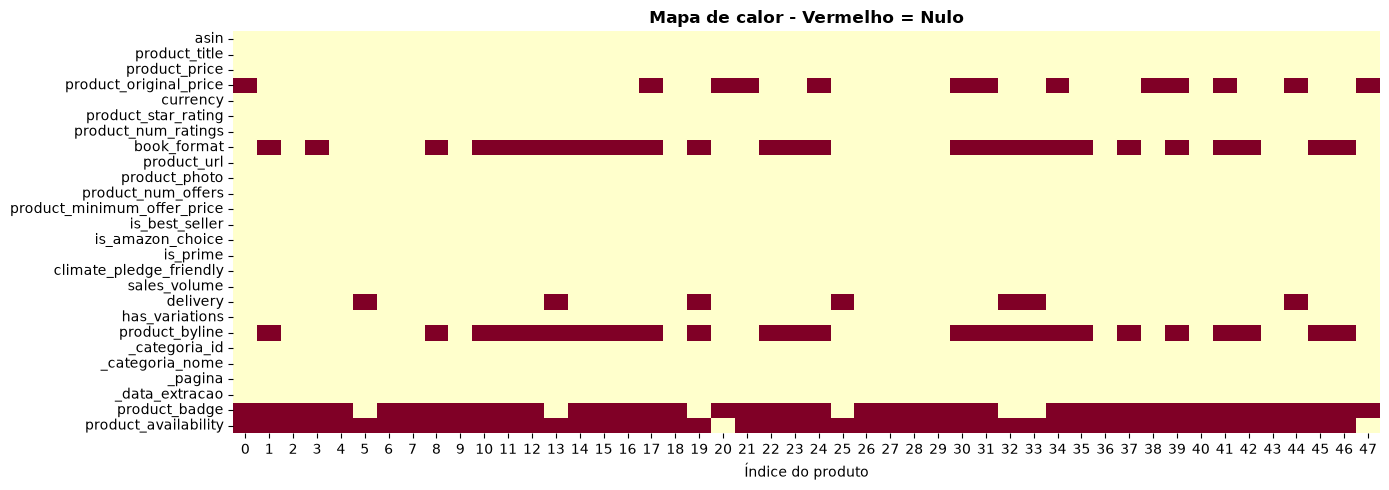

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    df.isnull().T,
    cbar=False,
    yticklabels=True,
    cmap="YlOrRd",
    ax=ax
)
ax.set_title("Mapa de calor - Vermelho = Nulo", fontweight="bold")
ax.set_xlabel("Índice do produto")
plt.tight_layout()
plt.show()

In [9]:
colunas_com_nulo = nulos[nulos["qtd_nulos"] > 0].index.tolist()

if colunas_com_nulo:
    print("Correlação de nulos entre colunas (1.0 = sempre nulos juntos):")
    print(df[colunas_com_nulo].isnull().corr().round(2).to_string())


Correlação de nulos entre colunas (1.0 = sempre nulos juntos):
                        product_availability  product_badge  book_format  product_byline  product_original_price  delivery
product_availability                    1.00          -0.08         0.24            0.23                   -0.34      0.09
product_badge                          -0.08           1.00        -0.08           -0.09                    0.23     -0.91
book_format                             0.24          -0.08         1.00            0.96                   -0.03      0.01
product_byline                          0.23          -0.09         0.96            1.00                   -0.00      0.02
product_original_price                 -0.34           0.23        -0.03           -0.00                    1.00     -0.12
delivery                                0.09          -0.91         0.01            0.02                   -0.12      1.00


In [10]:
print("product_price - amostras:")
for v in df["product_price"].unique()[:10]:
    print(f" '{v}'")

print("\nproduct_original_price - amostras (excluindo nulos):")
for v in df["product_original_price"].dropna().unique()[:10]:
    print(f" '{v}'")

product_price - amostras:
 'R$ 4.399,00'
 'R$ 1.047,00'
 'R$ 389,67'
 'R$ 144,09'
 'R$ 252,99'
 'R$ 2.128,77'
 'R$ 2.199,00'
 'R$ 429,00'
 'R$ 149,00'
 'R$ 4.599,00'

product_original_price - amostras (excluindo nulos):
 'R$ 1.379,00'
 'R$ 499,90'
 'R$ 219,00'
 'R$ 349,90'
 'R$ 2.699,90'
 'R$ 3.499,90'
 'R$ 222,54'
 'R$ 5.099,90'
 'R$ 214,90'
 'R$ 369,00'


In [11]:
total = len(df)
com_original = df["product_original_price"].notna().sum()
print(f"\nProdutos com preço original (desconto): {com_original} de {total} ({com_original / total * 100:.0f}%)")

padrao_ok = df["product_price"].str.match(r"R\$\s[\d.,]+", na=False)
fora_do_padrao = (~padrao_ok).sum()
print(f"\nPreços fora do padrão esperado: {fora_do_padrao}")
if fora_do_padrao > 0:
    print(df.loc[~padrao_ok, ["asin", "product_price"]])


Produtos com preço original (desconto): 35 de 48 (73%)

Preços fora do padrão esperado: 0


In [12]:
def parse_preco(val):
    if pd.isna(val): return None
    return float(re.sub(r"[R$\s.]", "", str(val)).replace(",", "."))

preco = df["product_price"].apply(parse_preco)

print("Estatísticas Descritivas:")
print(preco.describe().apply(lambda x: f"R$ {x:,.2f}"))
print()
print(f"Mediana: R$ {preco.median():,.2f}")
print(f"Media   : R$ {preco.mean():,.2f}")
print()

Estatísticas Descritivas:
count       R$ 48.00
mean       R$ 709.04
std      R$ 1,217.49
min          R$ 3.85
25%         R$ 39.38
50%        R$ 184.50
75%        R$ 434.02
max      R$ 4,599.00
Name: product_price, dtype: str

Mediana: R$ 184.50
Media   : R$ 709.04



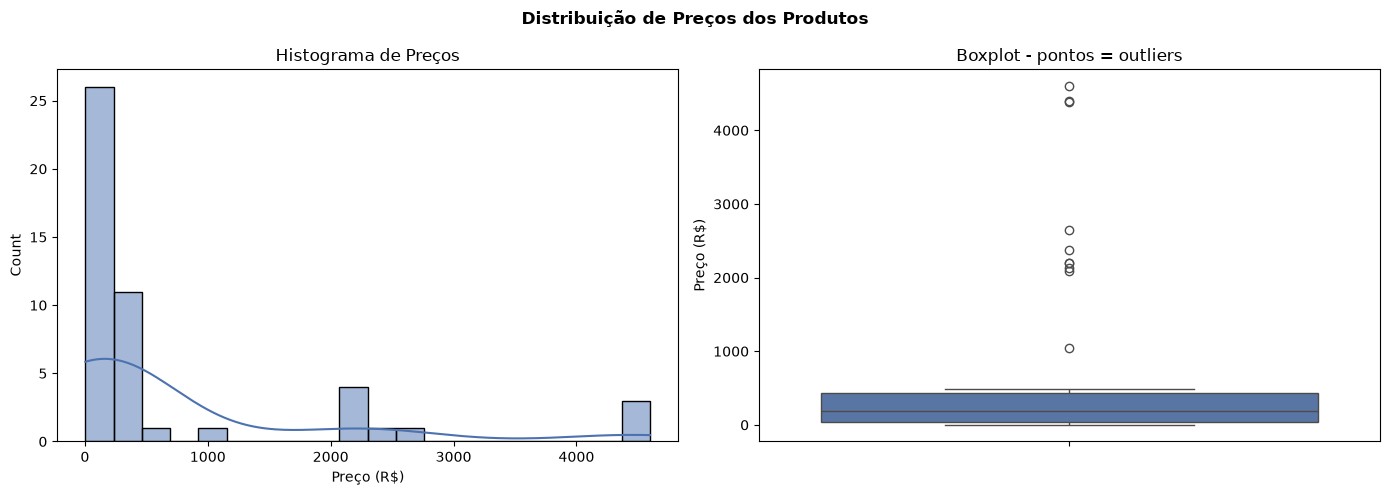

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(preco, bins=20, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Histograma de Preços")
axes[0].set_xlabel("Preço (R$)")

sns.boxplot(y=preco, ax=axes[1], color="#4c72b0")
axes[1].set_title("Boxplot - pontos = outliers")
axes[1].set_ylabel("Preço (R$)")

plt.suptitle("Distribuição de Preços dos Produtos", fontweight="bold")
plt.tight_layout()
plt.show()



In [14]:
preco_temp = df.copy()
preco_temp["preco_num"] = preco

print("5 mais caros:")
print(preco_temp.nlargest(5, "preco_num")[["product_title", "preco_num"]].to_string())

print("\n5 mais baratos: ")
print(preco_temp.nsmallest(5, "preco_num")[["product_title", "preco_num"]].to_string())

5 mais caros:
                                                                                                                                                                              product_title  preco_num
9                                                                                                                               PlayStation®5 Slim Disk - Pacote ASTRO BOT e Gran Turismo 7     4599.0
0                                                                                                                      PlayStation®5 Slim Digital 825GB – Pacote ASTRO BOT e Gran Turismo 7     4399.0
20          Nintendo, Console, Nintendo Switch 2, Nacional, Portátil e Doméstico, Bateria de até 9 Horas, Inclui Joy-Con com Suporte e Alças, 1 ano de Garantia - Modelo Nacional de Tomada     4389.0
47           Meta Quest 3S 128 GB — Mergulhe na realidade mista — Dispositivo irreal. Preço irreal. — Fone de ouvido multifuncional — Obtenha um teste de 3 meses do Meta Horizon+ incluído   

In [15]:
print("Todos os valores unicos de sales_volume")
for v in df["sales_volume"].value_counts().items():
    print(f"{v[1]:3d}x   '{v[0]}'")

Todos os valores unicos de sales_volume
 10x   'Mais de 2 mil compras no mês passado'
  9x   'Mais de 1 mil compras no mês passado'
  5x   'Mais de 3 mil compras no mês passado'
  4x   'Mais de 5 mil compras no mês passado'
  4x   'Mais de 300 compras no mês passado'
  4x   'Mais de 500 compras no mês passado'
  3x   'Mais de 4 mil compras no mês passado'
  3x   'Mais de 100 compras no mês passado'
  2x   'Mais de 700 compras no mês passado'
  1x   'Mais de 8 mil compras no mês passado'
  1x   'Mais de 600 compras no mês passado'
  1x   'Mais de 200 compras no mês passado'
  1x   'Mais de 800 compras no mês passado'


In [16]:
print("Primeiros 10 valores de delivery")
for i,v in enumerate(df["delivery"].dropna().unique()[:10]):
    print(f"{i:2d}. '{v}'")

print(f"\nNulos em delivery: {df['delivery'].isna().sum()} de {len(df)}")
print("Nulos em delivery significa que não tem entrega gratis?")

Primeiros 10 valores de delivery
 0. 'Entrega GRÁTIS: qui., 23 de jul. no seu primeiro pedido'
 1. 'Entrega GRÁTIS: ter., 14 de jul. no seu primeiro pedido'
 2. 'Entrega GRÁTIS: sex., 10 de jul. no seu primeiro pedido'
 3. 'Entrega GRÁTIS: 10 - 13 de jul.'
 4. 'Entrega GRÁTIS: sáb., 11 de jul. no seu primeiro pedido'
 5. 'Entrega GRÁTIS: dom., 12 de jul.'
 6. 'Entrega GRÁTIS: sex., 10 de jul. no seu primeiro pedidoOu entrega mais rápida: Amanhã 07:00 - 10:59'
 7. 'Entrega GRÁTIS: dom., 12 de jul. no seu primeiro pedido'
 8. 'Entrega GRÁTIS: Amanhã, 9 de jul. no seu primeiro pedido'
 9. 'Entrega GRÁTIS: dom., 19 de jul. no seu primeiro pedidoSomente 4 em estoque.'

Nulos em delivery: 7 de 48
Nulos em delivery significa que não tem entrega gratis?


In [17]:
print("Distribuição de book_fromat (incluindo nulos)")
print(df["book_format"].value_counts(dropna=False).to_string())

print(f"\nNulos: {df['book_format'].isna().sum()} de {len(df)}")
print("Interpretação: null = produtos sem plataforma específica (acessório geral)")

Distribuição de book_fromat (incluindo nulos)
book_format
NaN                        27
PlayStation 5              10
Sem Sistema Operacional     4
PlayStation 4               2
Nintendo Switch             2
Android                     1
Windows                     1
Meta Quest                  1

Nulos: 27 de 48
Interpretação: null = produtos sem plataforma específica (acessório geral)


In [18]:
colunas_boleanas = [
    "is_prime",
    "is_best_seller",
    "is_amazon_choice",
    "climate_pledge_friendly",
    "has_variations"
]

print(f"{'COLUNA':<25} {'True': >6} {'False': >6} {'% True':>8} VALE MANTER ?")
print("_" * 65)

for col in colunas_boleanas:
    t = int(df[col].sum())
    f = int((~df[col]).sum())
    pct = df[col].mean() * 100
    vale = "analisar" if pct < 5 else "sim"
    print(f"{col:<25} {t:>6} {f:>6} {pct:>7.1f}% {vale}")

COLUNA                      True  False   % True VALE MANTER ?
_________________________________________________________________
is_prime                       5     43    10.4% sim
is_best_seller                 0     48     0.0% analisar
is_amazon_choice               0     48     0.0% analisar
climate_pledge_friendly        5     43    10.4% sim
has_variations                 4     44     8.3% sim


Distribuição das avaliações:
count    48.00
mean      4.75
std       0.11
min       4.30
25%       4.70
50%       4.80
75%       4.80
max       4.90
Name: product_star_rating, dtype: float64

Produtos sem avaliação: 0



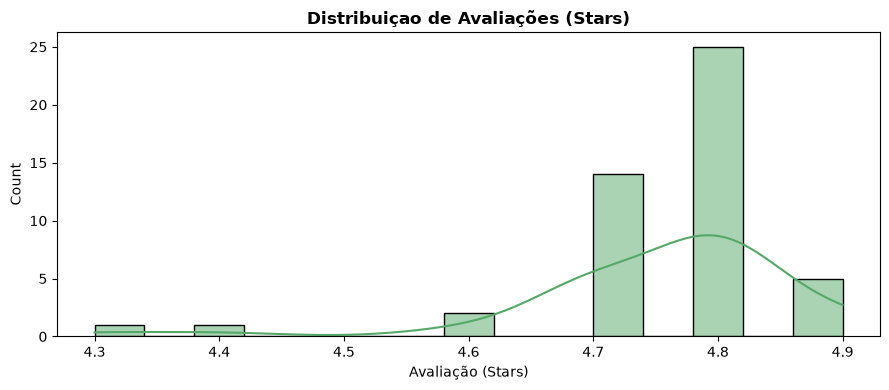

In [19]:
avaliacao = pd.to_numeric(df["product_star_rating"], errors="coerce")

print("Distribuição das avaliações:")
print(avaliacao.describe().round(2))
print()
print(f"Produtos sem avaliação: {avaliacao.isna().sum()}")
print()

fig, ax = plt.subplots(figsize=(9,4))
sns.histplot(avaliacao, bins=15, kde=True, ax=ax, color="#55A868")
ax.set_title("Distribuiçao de Avaliações (Stars)", fontweight="bold")
ax.set_xlabel("Avaliação (Stars)")
plt.tight_layout()
plt.show()

In [20]:
print("Distribuição do numero de avaliações:")
print(df["product_num_ratings"].describe().apply(lambda x: f"{x:,.0f}"))
print()

poucos = df[df["product_num_ratings"] < 100]
print(f"Produtos com menos de 100 avaliações: {len(poucos)}")
print(f"{'TÍTULO':<45} {'NOTA':>6} {'AVALIAÇÕES':>12}")
for _, row in poucos.iterrows():
    titulo = str(row["product_title"])[:43]
    Nota   = str(row["product_star_rating"])
    avals  = int(row["product_num_ratings"])
    print(f"{titulo: <45} {Nota:>6} {avals:>12,d}") 

Distribuição do numero de avaliações:
count        48
mean      9,063
std      13,129
min          71
25%         590
50%       4,690
75%      11,230
max      62,113
Name: product_num_ratings, dtype: str

Produtos com menos de 100 avaliações: 1
TÍTULO                                          NOTA   AVALIAÇÕES
Antena Interna de TV UHF HDTV AI 1115 Intel      4.3           71


In [21]:
total  = len(df)
unicos = df["asin"].nunique()
dup    = total - unicos

print(f"Total de registros : {total}")
print(f"ASINs únicos       : {unicos}")
print(f"Duplicatas         : {dup}")

if dup > 0:
    mask = df.duplicated("asin", keep=False)
    print("\nASINs duplicados:")
    print(df[mask][["asin", "product_title", "_data_extracao"]].to_string())
else:
    print("\nNenhuma duplicata encontrada nessa extração.")

Total de registros : 48
ASINs únicos       : 48
Duplicatas         : 0

Nenhuma duplicata encontrada nessa extração.


In [22]:
# COLUNAS_PtBr = {
#     "asin": "codigo_produto",
#     "product_title": "titulo_produto",
#     "product_price": "preco",
#     "product_original_price": "preco_original",
#     "currency": "moeda",
#     "product_star_rating": "avaliacao_media",
#     "product_num_ratings": "quantidade_avaliacoes",
#     "product_url": "url_produto",
#     "product_photo": "url_imagem",
#     "product_num_offers": "quantidade_ofertas",
#     "product_minimum_offer_price": "menor_preco_oferta",
#     "is_amazon_choice": "amazon_choice",
#     "is_prime": "prime",
#     "sales_volume": "volume_vendas",
#     "product_badge": "selo_produto",
#     "product_availability": "disponibilidade",
#     "coupon_text": "cupom",
#     "product_byline": "fabricante"
# }
# df = df.rename(columns=COLUNAS_PtBr)
# df.head(1)

In [23]:
# COLUNAS_VALOR = ['preco', 'preco_original', 'menor_preco_oferta'] 

# for col in COLUNAS_VALOR :
#     df[col] = (
#         df[col]
#         .str.replace('R$', '')
#         .str.replace('.', '')
#         .str.replace(',', '.')
#         .astype(float)
# )

In [24]:
# df['volume_vendas'] = df["volume_vendas"].str.extract(
#     r'(\d+(?:\s(?:mil?))?)'
# )